# AI usage

# Intro

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

## basic nnet classes

In [87]:
class Activation(): #base class for all activation functions
    def __init__(self,f,f_prime):
        self.f=f #activation function
        self.d=f_prime #derivative

    def __call__(self, n):
        return self.f(n)

# define specific activations
class Linear(Activation):
    def _linear(self,n):
        return n
    def _linear_prime(self,n):
        return np.ones_like(n)
    def __init__(self,):
        super().__init__(self._linear, self._linear_prime)

class PosLinear(Activation):
    def _poslin(self,n):
        return np.where(np.asarray(n) > 0, n, 0)
    def _poslin_prime(self,n):
        return np.where(np.asarray(n) > 0, 1, 0)
    def __init__(self,):
        super().__init__(self._poslin, self._poslin_prime)

class Sigmoid(Activation):
    def _sigmoid(self,n):
        return 1/(1+np.e**(-n))
    def _sigmoid_prime(self,n):
        return self._sigmoid(n)*(1-self._sigmoid(n))
    def __init__(self,):
        super().__init__(self._sigmoid, self._sigmoid_prime)

class GELU(Activation):
    # we use approximation, see https://onlinelibrary.wiley.com/doi/10.1155/2023/4229924 with some adjustment
    def _gelu(self, n):
        u = np.sqrt(2 / np.pi) * (n + 0.044715 * n**3)
        return 0.5 * n * (1 + np.tanh(u))

    def _gelu_prime(self, n):
        a = np.sqrt(2 / np.pi)
        u = a * (n + 0.044715 * n**3)
        t = np.tanh(u)

        return (
            0.5 * (1 + t)
            + 0.5 * n * (1 - t**2) * a
            * (1 + 3 * 0.044715 * n**2)
        )
    def __init__(self,):
        super().__init__(self._gelu, self._gelu_prime)

In [88]:
class Neuron():
    def __init__(self, weights, bias, activation:Activation): #activation should be callable, I was too lazy to do the imports for type hinting here
        weights=np.array(weights) #ensure this is array (shape = S*R where S is number of outputs, R is number of input features)
        if weights.ndim==1:#for single output case, reshape to 1*R
            weights=np.expand_dims(weights,axis=0)
        if bias is not None: 
            bias=np.array(bias)
            while bias.ndim<2:
                bias=np.expand_dims(bias,axis=1)
        
        self.W=weights
        self.S=weights.shape[0] #output features
        self.R=weights.shape[1]
        if bias is not None and bias.shape[0]!=self.S:
            raise ValueError(f'bias shape {bias.shape} not compatible with weight shape {weights.shape} at dim 0')
        self.b=bias #can be vector ot None
        self.activation=activation

        #lets keep track of a/n/sensitivity for each neuron in order to implement back propagation later
        self.a=0 #last activation
        self.n=0 #last net input
        self.s=0 #sensitivity
        
    def __call__(self, input): # i just learned  about this underscore method and wanted to implement it for this project
        return self.forward(input)

    def forward(self, input): #this should work for batch of inputs with shape n*R
        p=np.array(input)
        if p.ndim==1: #in case of single sample, reshape to 1*R
            p = p.reshape(-1,1)
        self.n=self.W@p
        if self.b is not None:
            self.n+=self.b
        self.a=self.activation(self.n)
        return self.a

In [89]:
class Layer():
    def __init__(self, neuron:Neuron|None=None, n_features:int=0, n_outputs:int=0, activation=Linear(),bias=True):
        self.neuron=neuron or self._make_neuron( n_features,n_outputs, activation, bias)
    def __call__(self, input):
            return self.forward(input)

    def _make_neuron(self, n_features:int=0, n_outputs:int=0, activation=None, bias=None):
        weights = np.random.randn(n_outputs, n_features)
        if bias: b = np.random.randn(n_outputs, 1)
        else: b=None
        return Neuron(weights,b,activation)
    
    def forward(self,input):
        a=self.neuron(input) #S*n
        return a 

In [90]:
class NeuralNet():
    def __init__(self, layers:list[Layer]|None=None, n_features:int=0, hidden_dim:int=0,n_hidden=0, activation:Activation=Sigmoid()):
        if layers is None:
            layers=[]
            layers.append(self._make_layer(n_features,hidden_dim,activation)) # input layer with n_neurons = S1 for R input features. Note each neuron produces a single output
            for _ in range(n_hidden):
                layers.append(self._make_layer(hidden_dim, hidden_dim,activation)) # hidden layers with shape S_(n-1)==S_n
            layers.append(self._make_layer(hidden_dim, 1,activation)) #output layer shapes final hidden layer size to desired output
        if layers is None or len(layers)==0:
            raise ValueError('layers not provided and random init failed')
        self.layers=layers
        self.a0=0

    def __call__(self,input):
        return self.forward(input)
    
    def _make_layer(self,n_features:int=0, n_outputs:int=0, activation: Activation=Sigmoid()):
        return Layer(n_features=n_features, n_outputs=n_outputs,bias=False, activation=activation)

    def forward(self, input):
        a = np.asarray(input)
        if a.ndim == 1:
            a = a.reshape(-1, 1)
        self.a0 = a #computed on each update
        for layer in self.layers:
            a = layer(a)
        return a

    def backward(self, error): #updates neuron sensitivities, not weights
        error = np.asarray(error)
        if error.ndim == 1:
            error = error.reshape(1, -1)

        previous_s = None
        previous_W = None
        for i, layer in enumerate(reversed(self.layers)):
            derivatives = layer.neuron.activation.d(layer.neuron.n)

            if i == 0: #initial sensitivity for E^2
                new_s = -2 * error * derivatives
            else: #backprop through hidden layers
                propagated = previous_W.T @ previous_s
                new_s = propagated * derivatives
            layer.neuron.s = new_s

            previous_W = layer.neuron.W
            previous_s = layer.neuron.s

## learning algorithms

In [91]:
class Optimizer(): #base optimizer class
    def __init__(self, network:NeuralNet, learning_rate):
        self.network=network
        self.lr=learning_rate

    def __call__(self, *args, **kwds):
        self.update()

    def update(self,labels,outputs):
        raise NotImplementedError()

class SteepestDescent(Optimizer):
    def __init__(self, network, learning_rate):
        super().__init__(network, learning_rate)

    def update(self): #overwrite method instead of using super
        a0=self.network.a0
        next_a=None
        for layer in self.network.layers:
            next_a=layer.neuron(a0) #calculate before updating
            dW=-self.lr*layer.neuron.s@a0.T
            layer.neuron.W+= dW
            if layer.neuron.b is not None:
                db=-self.lr*np.sum(layer.neuron.s,keepdims=True) #sum is the same as updating for each sample in batch
                layer.neuron.b+=db
            a0=next_a #update input to next layer

class MOBP(Optimizer):
    def __init__(self, network, learning_rate, gamma):
        super().__init__(network, learning_rate)
        self.gamma=gamma
        self._init_neurons()

    def _init_neurons(self):
        #add velocity for each neuron parameter
        for layer in self.network.layers:
            layer.neuron.delta_W=0
            layer.neuron.delta_b=0

    def update(self): #overwrite method instead of using super
        a0=self.network.a0
        next_a=None
        for layer in self.network.layers:
            next_a=layer.neuron(a0)
            dW=-self.lr*layer.neuron.s@a0.T

            layer.neuron.delta_W = (
                self.gamma * layer.neuron.delta_W
                + (1 - self.gamma) * self.lr * dW
            )
            layer.neuron.W += layer.neuron.delta_W
            
            if layer.neuron.b is not None:
                db=-self.lr*np.sum(layer.neuron.s,keepdims=True)
                layer.neuron.delta_b = (
                    self.gamma * layer.neuron.delta_b
                    + (1 - self.gamma) * self.lr * db
                )
                layer.neuron.b += layer.neuron.delta_b
            
            a0=next_a

Variable Learning Rate Backpropagation (VLBP)
1. If the squared error (over the entire training set) increases by more than some set percentage  (typically one to five percent) after a weight update, then the weight update is discarded, the learning rate is multiplied by some factor rho<1, and the momentum coefficient gamma (if it is used) is set to zero.
2. If the squared error decreases after a weight update, then the weight update is accepted and the learning rate is multiplied by some factor eta>1. If gamma has been previously set to zero, it is reset to its original value.
3. If the squared error increases by less than , then the weight update is accepted but the learning rate and the momentum coefficient are unchanged

In [92]:
class Trainer(): #base trainer, no variable learning rate 
    def __init__(self, network, optimizer, n_epochs, batch_size=None):
        self.network=network
        self.optimizer=optimizer
        self.n_epochs=n_epochs
        self.batch_size=batch_size
        self.lr_log=[]

    def _update_lr(self, lr): #added this in case we need to compare optimizer lr
        self.lr_log.append(lr)

    def _epoch(self, data, labels):
        n_samples = data.shape[1]
        batch_size = self.batch_size or n_samples #let batch size be none
        epoch_loss=0

        for start in range(0, n_samples, batch_size):
            stop = min(start + batch_size, n_samples)
            # forward pass
            x=data[:,start:stop]
            y=labels[:,start:stop]
            predictions = self.network(x)
            errors=y-predictions #shape = [n_outputs, n_samples]
            loss=errors@errors.T #note, this is reversed from textbook due to columns being samples
            # backprop
            self.network.backward(errors) #need to check if this should be loss
            self.optimizer()
            epoch_loss+=loss #store for later
        return epoch_loss/batch_size # average for all batches

    def train(self, data, labels):
        train_loss=[]
        for _ in range(self.n_epochs):
            train_loss.append(self._epoch(data,labels))
        return train_loss

In [93]:
class VLBP(Trainer): #inherit from original trainer class
    def __init__(self, network, optimizer:Optimizer, n_epochs, sensitivity=0.05, decrease_factor=0.1, increase_factor=1.1):
        super().__init__(network, optimizer, n_epochs)
        self.sensitivity=sensitivity
        self.decrease_factor=decrease_factor
        self.increase_factor=increase_factor
        self.original_gamma = getattr(optimizer, 'gamma', None)

    def _clone_weights(self): #added this  since we aren't supposed to import other libraries
        state = {}
        for i, layer in enumerate(self.network.layers):
            state[(i, 'W')] = layer.neuron.W.copy()
            if layer.neuron.b is not None:
                state[(i, 'b')] = layer.neuron.b.copy()
        return state

    def _restore_weights(self, state):
        for i, layer in enumerate(self.network.layers):
            layer.neuron.W = state[(i, 'W')].copy()
            if layer.neuron.b is not None:
                layer.neuron.b = state[(i, 'b')].copy()

    def train(self, data, labels):
            losses = []
            prev_loss = None
            weight_state = None

            for epoch in range(self.n_epochs):
                # Save weights before training
                
                weight_state = self._clone_weights()
                current_loss = self._epoch(data, labels)
                losses.append(current_loss)
                
                if prev_loss is None:
                    prev_loss = current_loss
                    continue
                    
                # Relative loss change
                rel_change = (current_loss - prev_loss) / prev_loss if prev_loss != 0 else float('inf')
                
                if rel_change < 0:  
                    self.optimizer.lr *= self.increase_factor
                    if hasattr(self.optimizer, 'gamma') and self.optimizer.gamma == 0:
                        self.optimizer.gamma = self.original_gamma
                        
                elif rel_change > self.sensitivity:  
                    self._restore_weights(weight_state)
                    self.optimizer.lr *= self.decrease_factor
                    if hasattr(self.optimizer, 'gamma'):
                        self.optimizer.gamma = 0
                    if hasattr(self.optimizer, '_init_neurons'):
                        self.optimizer._init_neurons()
                else:  
                    pass
                
                prev_loss = current_loss
                
            return losses

## basic example

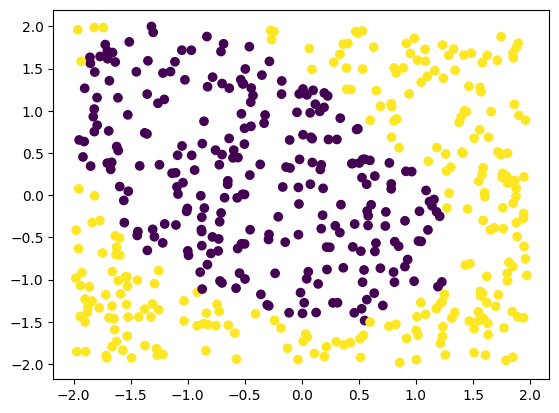

In [94]:
#create data
np.random.seed(42)

n_samples = 500
n_features=2
X = np.random.uniform(-2, 2, size=(n_features, n_samples))
x1 = X[0, :]
x2 = X[1, :]

# nonlinear labels
y = np.sin(x1) + x2**2 +x1**2 + x1 * x2
y=y.reshape(1,-1) # 1, n_samples

# convert nonlinear regression to classification
y_classification = (y > np.median(y)).astype(int) # this is effectively putting a loop on our data controlled by variance
y_classification = y_classification.reshape(1, -1)
plt.figure()
plt.scatter(x1,x2, c=y_classification)
plt.show()

In [95]:
nnet=NeuralNet(n_features=2,hidden_dim=10,n_hidden=2)
optimizer=MOBP(nnet, learning_rate=0.01,gamma=0.9)
n_epochs=2000
n_runs=2
trainer=VLBP(nnet,optimizer,n_epochs=n_epochs//n_runs)
loss=[]
predictions=[]
for _ in range(n_runs):
    loss.extend(trainer.train(X,y_classification))
    predictions.append(nnet(X))
loss=np.array(loss).flatten()

In [96]:
#save this model for later
with open('nnet.pkl', 'wb') as file:
    pickle.dump(nnet, file)

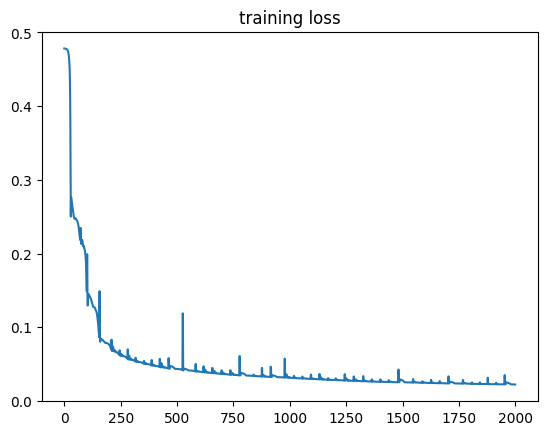

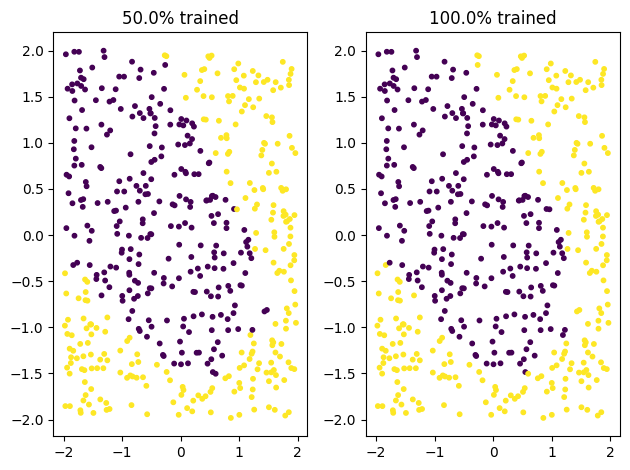

In [97]:
plt.figure()
plt.plot(loss)
plt.title('training loss')
plt.show()

fig, axs=plt.subplots(1,n_runs)
for i,pred in enumerate(predictions):
    ax=axs[i]
    ax.scatter(x1,x2,c=np.where(pred>0.5,1,0),s=10)
    
    ax.set_title(f'{(i+1)*100/n_runs}% trained')
plt.tight_layout()
plt.show()

# LoRa

## new classes

In [102]:
# to jump off I used heavy inspiration from https://mbrenndoerfer.com/writing/lora-mathematics-low-rank-adaptation-formulas
# for now we will ignore sclaing term alpha/r
class LoRaNeuron(Neuron): #inherit everything from neuron
    def __init__(self,pretrained_neuron:Neuron=None, weights=None, bias=None, activation=None,
                 lora_rank=0,lora_enabled=False):
        if pretrained_neuron is not None:
            self.W = np.asarray(pretrained_neuron.W).copy()
            self.S = pretrained_neuron.S
            self.R = pretrained_neuron.R
            self.b = pretrained_neuron.b.copy() if pretrained_neuron.b is not None else None
            self.activation = pretrained_neuron.activation
            self.a=0 #last activation
            self.n=0 #last net input
            self.s=0 #sensitivity
        else:
            super().__init__(weights, bias, activation)

     # LoRA specific fields
        self.lora_rank = lora_rank
        self.lora_enabled = lora_enabled
        self.A = None
        self.B = None
        self.accumulated_dA = None
        self.accumulated_dB = None
        self.p_forward = None # Store input for gradient computation

    def enable_lora(self,rank=None):
        if rank is not None:
            self.lora_rank=rank
        if self.W is None or (self.lora_rank is not None and self.lora_rank <= 0):
            raise(ValueError('weight and lorarank must be > 0'))
        self.A = np.random.randn(self.S, self.lora_rank)
        self.B = np.random.randn(self.lora_rank,self.R)
        self.lora_enabled = True
        self.reset_lora_gradients()

    def reset_lora_gradients(self):
        if self.A is not None and self.B is not None:
            self.accumulated_dA = np.zeros_like(self.A)
            self.accumulated_dB = np.zeros_like(self.B)

    def forward(self, input): #overwrite base forward method
        if not self.lora_enabled:
            return super().forward(input)

        p=np.array(input)
        if p.ndim==1: #in case of single sample, reshape to 1*R
            p = p.reshape(-1,1)
        self.n=(self.W+self.A@self.B)@p
        if self.b is not None:
            self.n+=self.b
        self.a=self.activation(self.n)

        self.p_forward = p.copy()
        return self.a


In [103]:
class LoRaNet(NeuralNet):
    def __init__(self, layers = None, n_features = 0, hidden_dim = 0, n_hidden=0, activation = Sigmoid(), 
                 pretrained_net:NeuralNet=None, freeze_weights=False):
        if pretrained_net is not None:
            super().__init__(layers=pretrained_net.layers)
        else:
            super().__init__(layers, n_features, hidden_dim, n_hidden, activation)
        
        for layer in self.layers:
            layer.neuron=LoRaNeuron(layer.neuron,lora_enabled=False) #convert to lora layers but dont set A/B yet
        self.freeze_weights=freeze_weights

    def init_lora(self,layer:int,rank:int,scale=1): #added rudimentary scale to prevent domination
        neuron=self.layers[layer].neuron
        neuron.enable_lora(rank)
        neuron.A*=scale
        neuron.B*=scale

    def enable_lora(self,layer,state=True):
        self.layers[layer].neuron.lora_enabled=state

    def reset_lora_grads(self):
        for layer in self.layers:
            layer.neuron.reset_lora_gradients()

    def backward(self, error):
        if not self.freeze_weights:
            return super().backward(error)
        else:
            super().backward(error) #update each neurons sensitivity only
            for layer in self.layers:
                neuron=layer.neuron
                if not neuron.lora_enabled or neuron.A is None:
                    continue #leave regular layers alone
                h=neuron.B@neuron.p_forward
                
                neuron.accumulated_dA += neuron.s @ h.T
                neuron.accumulated_dB += neuron.A.T @ neuron.s @ neuron.p_forward.T 

In [104]:
class LoRaSteepestDescent(Optimizer):
    def __init__(self, network:LoRaNet, learning_rate):
        super().__init__(network, learning_rate)

    def updateWeights(self): #overwrite method instead of using super
        a0=self.network.a0
        next_a=None
        for layer in self.network.layers:
            next_a=layer.neuron(a0) #calculate before updating
            dW=-self.lr*layer.neuron.s@a0.T
            layer.neuron.W+= dW
            if layer.neuron.b is not None:
                db=-self.lr*np.sum(layer.neuron.s,keepdims=True) #sum is the same as updating for each sample in batch
                layer.neuron.b+=db
            a0=next_a #update input to next layer

    def updateLoRa(self): #let student figure this out
        for layer in self.network.layers:
            neuron=layer.neuron
            if neuron.lora_enabled:
                neuron.A-= self.lr*neuron.accumulated_dA
                neuron.B-= self.lr*neuron.accumulated_dB
            neuron.reset_lora_gradients()

    def update(self):
        if not self.network.freeze_weights:
            self.updateWeights()
        else: 
            self.updateLoRa()

In [105]:
class LoRaMOBP(Optimizer):
    def __init__(self, network:LoRaNet, learning_rate):
        super().__init__(network, learning_rate)

    def updateWeights(self): #overwrite method instead of using super
        a0=self.network.a0
        next_a=None
        for layer in self.network.layers:
            next_a=layer.neuron(a0)
            dW=-self.lr*layer.neuron.s@a0.T

            layer.neuron.delta_W = (
                self.gamma * layer.neuron.delta_W
                + (1 - self.gamma) * self.lr * dW
            )
            layer.neuron.W += layer.neuron.delta_W
            
            if layer.neuron.b is not None:
                db=-self.lr*np.sum(layer.neuron.s,keepdims=True)
                layer.neuron.delta_b = (
                    self.gamma * layer.neuron.delta_b
                    + (1 - self.gamma) * self.lr * db
                )
                layer.neuron.b += layer.neuron.delta_b
            
            a0=next_a

    def updateLoRa(self): #let student figure this out
        for layer in self.network.layers:
            neuron=layer.neuron
            if neuron.lora_enabled:
                
                neuron.A-= self.lr*neuron.accumulated_dA
                neuron.B-= self.lr*neuron.accumulated_dB
            neuron.reset_lora_gradients()

    def update(self):
        if not self.network.freeze_weights:
            self.updateWeights()
        else: 
            self.updateLoRa()

In [171]:
def count_weights(net:NeuralNet):
    n_params=0
    for layer in net.layers:
        neuron=layer.neuron
        n_params+=neuron.W.size
        if neuron.b is not None:
            n_params+=neuron.b.size

    return n_params

def count_lora_params(net:LoRaNet):
    n_params=0
    n_lora=0
    for layer in net.layers:
        neuron=layer.neuron
        n_params+=neuron.W.size
        if neuron.b is not None:
            n_params+=neuron.b.size
        if neuron.A is not None:
            n_lora+=neuron.A.size
            n_lora+=neuron.B.size
    return (n_params, n_lora)
    

## pretrained example

In [21]:
with open('nnet.pkl', 'rb') as file:
    pretrained = pickle.load(file)
loranet=LoRaNet(pretrained_net=pretrained, freeze_weights=True)
loranet.init_lora(1,2)

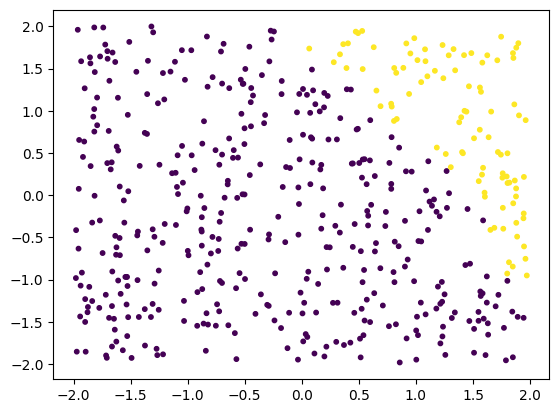

In [22]:
out=loranet(X)
loranet.backward(y_classification-out)
loranet.reset_lora_grads()
plt.scatter(x1,x2,c=np.where(out>0.5,1,0),s=10)

## full training example

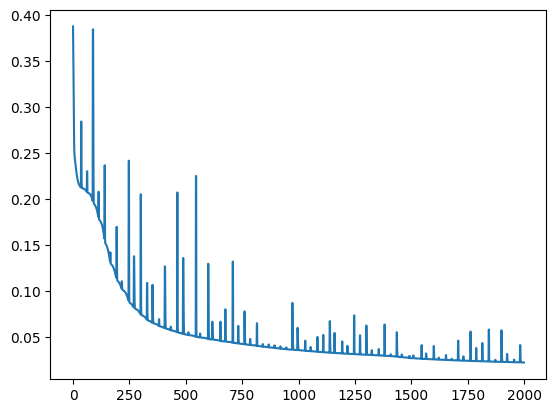

In [185]:
nnet=LoRaNet(n_features=2,hidden_dim=10,n_hidden=1,freeze_weights=False)
optimizer=LoRaSteepestDescent(nnet, learning_rate=0.001)
n_epochs=2000
n_runs=2
trainer=VLBP(nnet,optimizer,n_epochs=n_epochs//n_runs)
loss=[]
predictions=[]
for _ in range(n_runs):
    loss.extend(trainer.train(X,y_classification))
    predictions.append(nnet(X))
loss=np.array(loss).flatten()
plt.plot(loss)

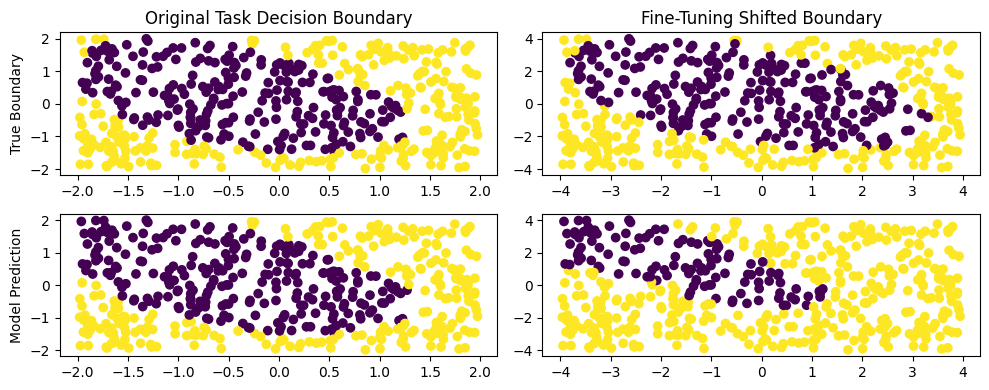

In [186]:
# create new data:
np.random.seed(42)
n_samples=500
X_fine = np.random.uniform(-4, 4, size=(n_features, n_samples)) #adjusted bounds
x1_f, x2_f = X_fine[0], X_fine[1]
y_raw = np.sin(x1_f + 0.4) + (x2_f - 0.5)**2 + x1_f**2 + x1_f * x2_f + 0.6 #added subtle variation here
y_fine = (y_raw > np.median(y_raw)).astype(int).reshape(1, -1)

# Visualize both boundaries side-by-side with model performance
out_original=nnet(X)
out_new=nnet(X_fine)
fig, axes = plt.subplots(2, 2, figsize=(10, 4))
for i,row in enumerate(axes):
    if i==0:
        row[0].scatter(x1, x2, c=y_classification)
        row[0].set_title('Original Task Decision Boundary')
        row[0].set_ylabel('True Boundary')
        row[1].scatter(x1_f, x2_f, c=y_fine)
        row[1].set_title('Fine-Tuning Shifted Boundary')

    else:
        row[0].scatter(x1, x2, c=out_original.round())
        row[0].set_ylabel('Model Prediction')
        row[1].scatter(x1_f, x2_f, c=out_new.round())

plt.tight_layout()
plt.show()

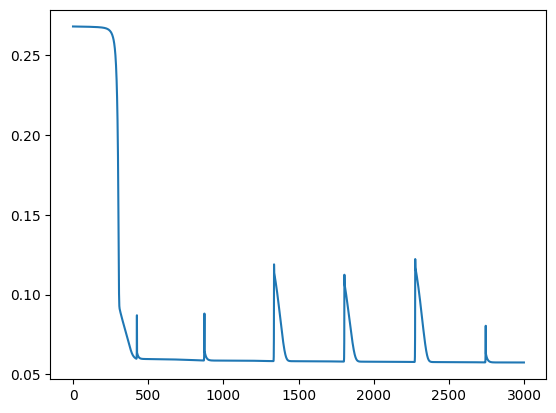

In [189]:
#add lora layer and freeze weights
nnet.init_lora(1,rank=1, scale=0.1)
nnet.freeze_weights=True

optimizer=LoRaSteepestDescent(nnet, learning_rate=5e-5)
n_epochs=3000
n_runs=2
trainer=VLBP(nnet,optimizer,n_epochs=n_epochs//n_runs,increase_factor=1.01, decrease_factor=0.1)
loss=[]
predictions=[]
for _ in range(n_runs):
    loss.extend(trainer.train(X_fine,y_fine))
    predictions.append(nnet(X_fine))
loss=np.array(loss).flatten()

plt.figure()
plt.plot(loss)
plt.show()

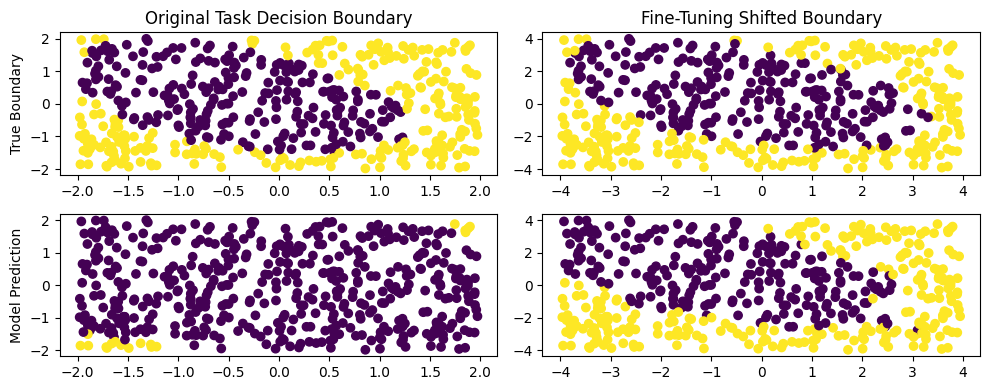

(130, 20)


In [190]:
out_original=nnet(X)
out_new=nnet(X_fine)
# Visualize both boundaries side-by-side with model performance
fig, axes = plt.subplots(2, 2, figsize=(10, 4))
for i,row in enumerate(axes):
    if i==0:
        row[0].scatter(x1, x2, c=y_classification)
        row[0].set_title('Original Task Decision Boundary')
        row[0].set_ylabel('True Boundary')
        row[1].scatter(x1_f, x2_f, c=y_fine)
        row[1].set_title('Fine-Tuning Shifted Boundary')

    else:
        row[0].scatter(x1, x2, c=out_original.round())
        row[0].set_ylabel('Model Prediction')
        row[1].scatter(x1_f, x2_f, c=out_new.round())

plt.tight_layout()
plt.show()
print(count_lora_params(nnet))